# Person B: Feature Selection and Sensor Cost

**Research question 2:** How few features and sensors does a phone need to
recognize activity well? Fewer features mean less computation on the phone,
and dropping the gyroscope saves battery.

**Sections**
1. Setup and data loading
2. Ranking features three ways (random forest, mutual information, L1
   logistic regression) and how much the rankings agree
3. Accuracy vs. number of features
4. Recursive feature elimination (RFECV)
5. Sensor comparison: accelerometer only vs. gyroscope only vs. both
6. PCA vs. feature selection
7. Final test-set comparison and recommendation

**Model.** Every experiment retrains Person A's best model, a standardized
linear SVM with `C = 0.1` (test macro F1 0.963 on all 561 features), so the
only thing that changes is the input features.

**Evaluation protocol.** Same as Person A: 5-fold `GroupKFold` on the
training set, grouped by subject. In Section 3 the features are **ranked
again inside every training fold**, so the validation people never
influence which features are chosen. Ranking once on the full training set
and then cross-validating would leak information and overstate accuracy.
Choices (ranking method, number of features) are made from cross-validation
only. The test set (9 unseen people) is scored once per final model in
Section 7. Test curves in Section 3 are shown for reference only and are
not used to choose anything.

## 1. Setup and data loading

In [1]:
import re
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

sys.path.insert(0, str(Path.cwd().parent))
from src.har_data import ACTIVITY_NAMES, load_features, sensor_masks
from src.evaluation import (RANDOM_STATE, cv_score, evaluate_on_test,
                            group_cv, save_figure, save_results)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

data = load_features()
X_train, X_test = data.X_train, data.X_test
y_train, y_test = data.y_train, data.y_test
groups = data.subject_train
feature_names = np.array(data.feature_names)
masks = sensor_masks(data.feature_names)
labels = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Accelerometer features:", masks["accelerometer"].sum())
print("Gyroscope features:", masks["gyroscope"].sum())

Train: (7352, 561) Test: (2947, 561)
Accelerometer features: 348
Gyroscope features: 213


In [2]:
def best_model():
    """Return a fresh copy of Person A's best model (tuned linear SVM)."""
    return make_pipeline(
        StandardScaler(),
        LinearSVC(C=0.1, max_iter=10000, random_state=RANDOM_STATE),
    )


def score(y_true, y_pred):
    """Return accuracy and macro F1 as a dict."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

## 2. Ranking features three ways

Each method orders all 561 features from most to least useful:

* **Random forest importance.** Mean decrease in impurity from 300 trees.
  It captures non-linear effects and interactions, but it spreads credit
  across correlated features.
* **Mutual information** (the score behind `SelectKBest`). How much knowing
  one feature reduces uncertainty about the activity. Each feature is
  scored on its own, so redundant features can all rank highly.
* **L1-regularized logistic regression** (one-vs-rest). The L1 penalty
  drives most weights to exactly zero. We rank features by how early they
  enter the model as the penalty is relaxed (`C` = 0.01, 0.05, 0.2, 1),
  and break ties by the size of the weight. Unlike mutual information, this
  favors features that add *new* information.

In [3]:
L1_C_PATH = (0.01, 0.05, 0.2, 1.0)
METHODS = ("Random forest", "Mutual information", "L1 logistic")


def _l1_order(X, y):
    """Order features by the strength of L1 penalty at which they enter."""
    X_std = StandardScaler().fit_transform(X)
    n_features = X_std.shape[1]
    entry_step = np.full(n_features, len(L1_C_PATH))
    weight = np.zeros(n_features)
    for step, c_value in enumerate(L1_C_PATH):
        model = OneVsRestClassifier(
            LogisticRegression(l1_ratio=1.0, C=c_value, solver="liblinear",
                               max_iter=2000, random_state=RANDOM_STATE),
            n_jobs=-1,
        ).fit(X_std, y)
        coef = np.abs(np.vstack([est.coef_ for est in model.estimators_]))
        max_weight = coef.max(axis=0)
        new = (max_weight > 0) & (entry_step == len(L1_C_PATH))
        entry_step[new] = step
        weight[new] = max_weight[new]
    # Sort by entry step first, then by larger weight.
    return np.lexsort((-weight, entry_step))


def rank_features(method, X, y):
    """Return feature column indices ordered from most to least important.

    Parameters
    ----------
    method : str
        One of METHODS.
    X : DataFrame
        Training features (only the rows the ranking may see).
    y : ndarray
        Activity labels for those rows.
    """
    if method == "Random forest":
        forest = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=RANDOM_STATE)
        forest.fit(X, y)
        return np.argsort(-forest.feature_importances_, kind="stable")
    if method == "Mutual information":
        mi = mutual_info_classif(X, y, random_state=RANDOM_STATE, n_jobs=-1)
        return np.argsort(-mi, kind="stable")
    if method == "L1 logistic":
        return _l1_order(X, y)
    raise ValueError(f"Unknown method: {method}")

In [4]:
start = time.perf_counter()
full_rankings = {m: rank_features(m, X_train, y_train) for m in METHODS}
print(f"Ranked all features three ways in {time.perf_counter() - start:.1f} s")

rank_table = pd.DataFrame(index=feature_names)
for method, order in full_rankings.items():
    ranks = np.empty(len(order), dtype=int)
    ranks[order] = np.arange(1, len(order) + 1)
    rank_table[method] = ranks
rank_table["mean rank"] = rank_table[list(METHODS)].mean(axis=1)
rank_table = rank_table.sort_values("mean rank")
save_results(rank_table, "B_feature_rankings")

top20 = pd.DataFrame(
    {m: feature_names[order[:20]] for m, order in full_rankings.items()},
    index=pd.RangeIndex(1, 21, name="rank"),
)
display(top20)

Ranked all features three ways in 9.1 s


,Random forest,Mutual information,L1 logistic
rank,,,
1,tGravityAcc-mean()-X,tBodyAcc-max()-X,tGravityAcc-min()-X
2,tGravityAcc-min()-X,tGravityAcc-min()-Y,fBodyAccMag-energy()
3,"angle(X,gravityMean)",tBodyAccJerk-max()-X,tGravityAcc-mean()-X
4,tGravityAcc-mean()-Y,tGravityAcc-max()-Y,tGravityAcc-max()-X
5,tGravityAcc-energy()-X,tBodyAccMag-max(),"fBodyAcc-bandsEnergy()-1,8"
6,tGravityAcc-min()-Y,tGravityAccMag-max(),tBodyAccJerk-entropy()-Z
7,tGravityAcc-max()-Y,tBodyAccJerk-max()-Y,fBodyAccJerk-max()-Y
8,"angle(Y,gravityMean)",fBodyAcc-std()-X,tGravityAcc-max()-Y
9,tGravityAcc-max()-X,"fBodyAcc-bandsEnergy()-1,16",tBodyGyroJerk-entropy()-X


### 2.1 Do the three rankings agree?

Overlap of the top-20 lists. The diagonal is 20 by definition.

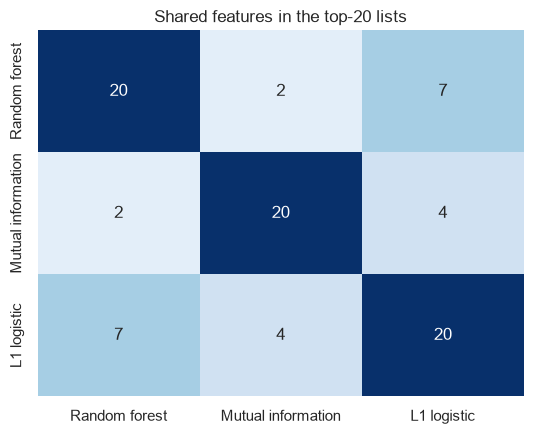

Features in all three top-20 lists (2):
   tGravityAcc-max()-Y
   tGravityAcc-min()-Y
Random forest        top 20: 100% accelerometer
Mutual information   top 20: 100% accelerometer
L1 logistic          top 20: 80% accelerometer


In [5]:
top20_sets = {m: set(top20[m]) for m in METHODS}
overlap = pd.DataFrame(
    [[len(top20_sets[a] & top20_sets[b]) for b in METHODS] for a in METHODS],
    index=METHODS, columns=METHODS,
)
in_all_three = set.intersection(*top20_sets.values())
save_results(overlap, "B_top20_overlap")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", vmin=0, vmax=20,
            cbar=False, ax=ax)
ax.set_title("Shared features in the top-20 lists")
fig.tight_layout()
save_figure(fig, "B_top20_overlap")
plt.show()

print(f"Features in all three top-20 lists ({len(in_all_three)}):")
for name in sorted(in_all_three):
    print("  ", name)

for method in METHODS:
    top = top20[method]
    acc_share = masks["accelerometer"][
        np.isin(feature_names, top)].mean()
    print(f"{method:20s} top 20: {acc_share:.0%} accelerometer")

**Observations.** The three methods agree on the *type* of feature but not on the exact list. Only 2 features appear in all three top-20 lists (the Y-axis gravity maximum and minimum).

* **Random forest** puts almost only **gravity** features at the top (mean, min, max and energy of `tGravityAcc`, plus the three `angle(·, gravityMean)` features). These describe how the phone is oriented, which separates lying, sitting and standing from each other.
* **Mutual information** prefers **body-motion intensity** features (max, std and low-frequency band energy of `tBodyAcc` and `tBodyAccJerk`). These separate moving from still. Many of them are near-duplicates of each other, because mutual information scores each feature on its own.
* **L1 logistic regression** mixes both kinds and adds a few gyroscope features. It picks features that add new information, so it avoids redundant copies.

All 20 random forest and mutual information picks, and 16 of 20 L1 picks, come from the accelerometer. This already suggests the gyroscope is not essential.

## 3. Accuracy vs. number of features

For k = 5 to 561, keep only the top-k features from each ranking and
retrain the linear SVM. The rankings are recomputed inside every training
fold. PCA (top k principal components) is included in the same loop and
discussed in Section 6.

In [6]:
K_VALUES = (5, 10, 20, 30, 50, 75, 100, 200, 350, 561)


def selection_curve(X, y, groups, methods, k_values):
    """Grouped-CV macro F1 and accuracy for top-k features of each method.

    Rankings are computed on each training fold only. PCA components are
    fit on the training fold as well.

    Returns
    -------
    DataFrame
        One row per (method, k, fold).
    """
    rows = []
    folds = group_cv().split(X, y, groups)
    for fold, (train_idx, val_idx) in enumerate(folds):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        for method in methods:
            order = rank_features(method, X_tr, y_tr)
            for k in k_values:
                cols = order[:k]
                model = best_model().fit(X_tr.iloc[:, cols], y_tr)
                pred = model.predict(X_val.iloc[:, cols])
                rows.append({"method": method, "k": k, "fold": fold,
                             **score(y_val, pred)})
        for k in k_values:
            n_comp = min(k, X.shape[1])
            model = make_pipeline(
                StandardScaler(), PCA(n_components=n_comp,
                                      random_state=RANDOM_STATE),
                LinearSVC(C=0.1, max_iter=10000, random_state=RANDOM_STATE),
            ).fit(X_tr, y_tr)
            rows.append({"method": "PCA", "k": k, "fold": fold,
                         **score(y_val, model.predict(X_val))})
        print(f"fold {fold + 1}/5 done")
    return pd.DataFrame(rows)


start = time.perf_counter()
curve_folds = selection_curve(X_train, y_train, groups, METHODS, K_VALUES)
print(f"Finished in {time.perf_counter() - start:.0f} s")

curve = (curve_folds.groupby(["method", "k"])[["f1_macro", "accuracy"]]
         .agg(["mean", "std"]))
curve.columns = ["cv_f1_macro", "cv_f1_std", "cv_accuracy", "cv_accuracy_std"]
curve = curve.reset_index()
save_results(curve, "B_selection_curve_cv")
display(curve.pivot(index="k", columns="method", values="cv_f1_macro"))

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done
Finished in 145 s


method,L1 logistic,Mutual information,PCA,Random forest
k,,,,
5,0.7722,0.7472,0.7715,0.5613
10,0.8691,0.7836,0.8207,0.5898
20,0.9188,0.8186,0.8684,0.8697
30,0.9206,0.8586,0.8744,0.8975
50,0.9297,0.9148,0.8946,0.9027
75,0.9287,0.9170,0.9022,0.9071
100,0.9358,0.9125,0.9100,0.9197
200,0.9363,0.9232,0.9243,0.9231
350,0.9390,0.9234,0.9362,0.9329


In [7]:
full_cv_f1 = curve.query("k == 561 and method == 'Random forest'")[
    "cv_f1_macro"].item()
TOLERANCE = 0.01  # accept up to 1 point of macro F1 below all features


def smallest_k_within(curve_df, method, target):
    '''Smallest k whose mean CV macro F1 is at least `target`.'''
    rows = curve_df[(curve_df["method"] == method)
                    & (curve_df["cv_f1_macro"] >= target)]
    return int(rows["k"].min()) if len(rows) else None


# Choose the ranking method by its average CV F1 in the cheap range (k <= 50).
cheap = curve[(curve["k"] <= 50) & curve["method"].isin(METHODS)]
best_method = cheap.groupby("method")["cv_f1_macro"].mean().idxmax()
k_best = smallest_k_within(curve, best_method, full_cv_f1 - TOLERANCE)

print(f"All 561 features, CV macro F1: {full_cv_f1:.4f}")
print("Mean CV macro F1 for k <= 50:")
print(cheap.groupby("method")["cv_f1_macro"].mean().round(4).to_string())
print(f"\nBest ranking method: {best_method}")
print(f"Smallest k within {TOLERANCE:.0%} of all features: {k_best}")
for method in METHODS:
    print(f"  {method:20s} -> k = "
          f"{smallest_k_within(curve, method, full_cv_f1 - TOLERANCE)}")

All 561 features, CV macro F1: 0.9362
Mean CV macro F1 for k <= 50:
method
L1 logistic           0.8821
Mutual information    0.8246
Random forest         0.7642

Best ranking method: L1 logistic
Smallest k within 1% of all features: 50
  Random forest        -> k = 350
  Mutual information   -> k = 561
  L1 logistic          -> k = 50


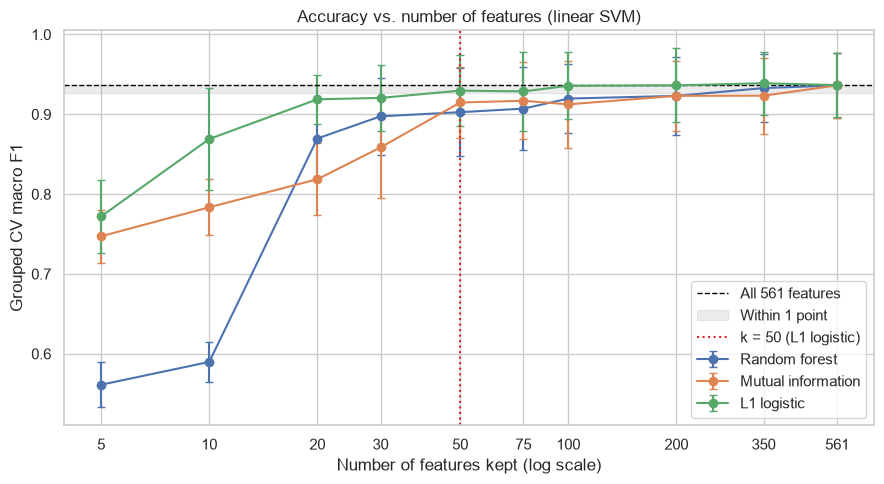

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for method in METHODS:
    part = curve[curve["method"] == method]
    ax.errorbar(part["k"], part["cv_f1_macro"], yerr=part["cv_f1_std"],
                marker="o", capsize=3, label=method)
ax.axhline(full_cv_f1, color="black", linestyle="--", linewidth=1,
           label="All 561 features")
ax.axhspan(full_cv_f1 - TOLERANCE, full_cv_f1, color="grey", alpha=0.15,
           label="Within 1 point")
ax.axvline(k_best, color="tab:red", linestyle=":",
           label=f"k = {k_best} ({best_method})")
ax.set_xscale("log")
ax.set_xticks(K_VALUES)
ax.set_xticklabels(K_VALUES)
ax.set_xlabel("Number of features kept (log scale)")
ax.set_ylabel("Grouped CV macro F1")
ax.set_title("Accuracy vs. number of features (linear SVM)")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "B_accuracy_vs_features")
plt.show()

**Reference only: the same curve on the test set.** Rankings are fit on
the whole training set. This checks that the cross-validation curve
carries over to new people. It is not used to choose k.

In [9]:
test_rows = []
for method, order in full_rankings.items():
    for k in K_VALUES:
        cols = order[:k]
        model = best_model().fit(X_train.iloc[:, cols], y_train)
        pred = model.predict(X_test.iloc[:, cols])
        test_rows.append({"method": method, "k": k, **score(y_test, pred)})
test_curve = pd.DataFrame(test_rows)
save_results(test_curve, "B_selection_curve_test")
display(test_curve.pivot(index="k", columns="method", values="f1_macro"))

method,L1 logistic,Mutual information,Random forest
k,,,
5,0.7198,0.7057,0.4849
10,0.8607,0.7497,0.5126
20,0.8781,0.7651,0.8105
30,0.9273,0.8333,0.8562
50,0.9416,0.8843,0.8952
75,0.9550,0.8941,0.9035
100,0.9471,0.9092,0.9249
200,0.9619,0.9467,0.9568
350,0.9643,0.9485,0.9677


**Observations.**

* **L1 logistic is clearly the best ranking for small feature budgets.** With only 20 features it reaches CV macro F1 0.919. Mutual information reaches 0.819 and random forest 0.870. At k = 5 to 10 the random forest ranking is poor (0.56 to 0.59), because its top picks are all gravity features that describe posture but cannot tell walking from walking upstairs.
* **Where accuracy levels off.** Using the L1 ranking, **50 features (9% of 561) reach CV macro F1 0.930, within 1 point of all 561 features (0.936)**. After about 100 features the curve is flat. Random forest needs about 350 features and mutual information all 561 to get within 1 point. This is the redundancy problem from Section 2.1: their top-k lists repeat the same information.
* **The test curve has the same shape**, with L1 the best ranking at every small k. On the test set the drop from 561 to 50 features is a bit larger (0.963 to 0.942) than in cross-validation. 75 to 200 features recover almost all of it (0.955 to 0.962). We report k = 50 because it was chosen by cross-validation. Choosing k from the test curve would be tuning on the test set.

## 4. Recursive feature elimination (RFECV)

RFE starts with all 561 features, fits the linear SVM, removes the 10
features with the smallest weights, and repeats. `RFECV` scores every
subset size with the same grouped folds. Elimination happens inside each
fold, so this curve has no selection leakage either.

RFECV finished in 143 s
Best subset size: 121 (CV macro F1 0.9442)
Smallest subset within 1 point of all features: 71


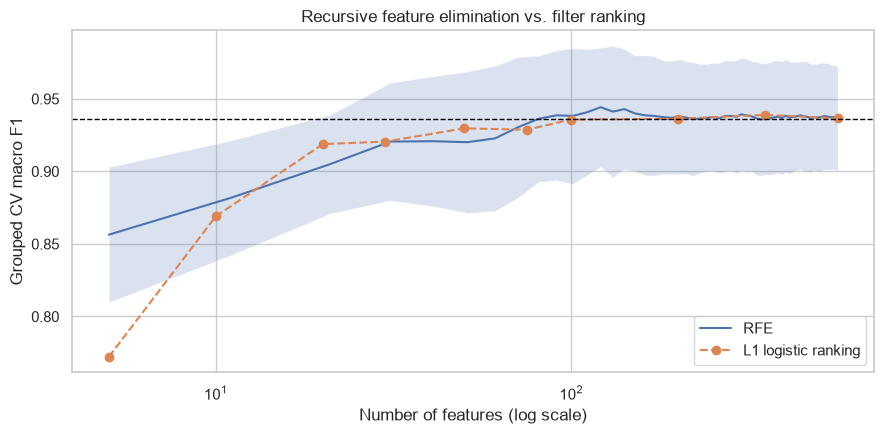

In [10]:
start = time.perf_counter()
rfecv = RFECV(
    estimator=best_model(),
    step=10,
    min_features_to_select=5,
    cv=group_cv(),
    scoring="f1_macro",
    importance_getter="named_steps.linearsvc.coef_",
    n_jobs=-1,
)
rfecv.fit(X_train, y_train, groups=groups)
print(f"RFECV finished in {time.perf_counter() - start:.0f} s")

rfe_curve = pd.DataFrame({
    "n_features": rfecv.cv_results_["n_features"],
    "cv_f1_macro": rfecv.cv_results_["mean_test_score"],
    "cv_f1_std": rfecv.cv_results_["std_test_score"],
})
save_results(rfe_curve, "B_rfecv")
rfe_k = smallest_k_within(
    rfe_curve.rename(columns={"n_features": "k"}).assign(method="RFE"),
    "RFE", full_cv_f1 - TOLERANCE)
print(f"Best subset size: {rfecv.n_features_} "
      f"(CV macro F1 {rfe_curve['cv_f1_macro'].max():.4f})")
print(f"Smallest subset within 1 point of all features: {rfe_k}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rfe_curve["n_features"], rfe_curve["cv_f1_macro"], label="RFE")
ax.fill_between(rfe_curve["n_features"],
                rfe_curve["cv_f1_macro"] - rfe_curve["cv_f1_std"],
                rfe_curve["cv_f1_macro"] + rfe_curve["cv_f1_std"], alpha=0.2)
best_part = curve[curve["method"] == best_method]
ax.plot(best_part["k"], best_part["cv_f1_macro"], "o--",
        label=f"{best_method} ranking")
ax.axhline(full_cv_f1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Number of features (log scale)")
ax.set_ylabel("Grouped CV macro F1")
ax.set_title("Recursive feature elimination vs. filter ranking")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "B_rfecv")
plt.show()

**Observations.** RFE, which removes features one batch at a time with the SVM itself, finds the best CV score of all methods: **macro F1 0.944 with 121 features**. That is slightly *better* than all 561, because dropping noisy features helps the linear model. The smallest RFE subset within 1 point of all features has 71 features. That is more than the L1 ranking needs (50), so the single L1 fit is both cheaper to compute and better for very small budgets. RFE is the better choice when the goal is the highest accuracy with a moderate number of features.

## 5. Sensor comparison

The gyroscope draws considerably more power than the accelerometer, so an
accelerometer-only app would last longer on battery. `sensor_masks()`
splits the 561 features into 348 accelerometer features (including the
gravity-angle features) and 213 gyroscope features.

In [11]:
sensor_sets = {
    "Accelerometer only": masks["accelerometer"],
    "Gyroscope only": masks["gyroscope"],
    "Both sensors": np.ones(len(feature_names), dtype=bool),
}
sensor_rows = {}
for name, mask in sensor_sets.items():
    cols = X_train.columns[mask]
    cv = cv_score(best_model(), X_train[cols], y_train, groups)
    test, _ = evaluate_on_test(best_model(), X_train[cols], y_train,
                               X_test[cols], y_test)
    sensor_rows[name] = {"n_features": int(mask.sum()), **cv, **test}
sensor_table = pd.DataFrame(sensor_rows).T
save_results(sensor_table, "B_sensor_comparison")
display(sensor_table[["n_features", "cv_f1_macro", "cv_accuracy",
                      "test_f1_macro", "test_accuracy"]])

,n_features,cv_f1_macro,cv_accuracy,test_f1_macro,test_accuracy
Accelerometer only,348.0,0.9065,0.9063,0.9122,0.9101
Gyroscope only,213.0,0.7797,0.7771,0.8308,0.8283
Both sensors,561.0,0.9364,0.9374,0.9629,0.9620


### 5.1 Accelerometer only, with feature selection

Can we drop the gyroscope **and** keep only a few features? We rank the
348 accelerometer features with the best method from Section 3, again
inside each fold.

In [12]:
acc_cols = X_train.columns[masks["accelerometer"]]
acc_k_values = tuple(k for k in K_VALUES if k < len(acc_cols)) + (
    len(acc_cols),)
acc_folds = selection_curve(X_train[acc_cols], y_train, groups,
                            (best_method,), acc_k_values)
acc_curve = (acc_folds[acc_folds["method"] == best_method]
             .groupby("k")[["f1_macro", "accuracy"]].agg(["mean", "std"]))
acc_curve.columns = ["cv_f1_macro", "cv_f1_std", "cv_accuracy",
                     "cv_accuracy_std"]
acc_curve = acc_curve.reset_index().assign(method="Accelerometer only")
save_results(acc_curve, "B_accel_only_curve_cv")

acc_full_f1 = acc_curve["cv_f1_macro"].iloc[-1]
k_acc = smallest_k_within(acc_curve, "Accelerometer only",
                          acc_full_f1 - TOLERANCE)
print(f"Accelerometer only, all {len(acc_cols)} features: CV F1 "
      f"{acc_full_f1:.4f}")
print(f"Smallest k within 1 point of that: {k_acc}")
display(acc_curve[["k", "cv_f1_macro", "cv_f1_std", "cv_accuracy"]])

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done
Accelerometer only, all 348 features: CV F1 0.9065
Smallest k within 1 point of that: 30


,k,cv_f1_macro,cv_f1_std,cv_accuracy
0,5,0.8584,0.0412,0.8644
1,10,0.8887,0.0510,0.8926
2,20,0.8959,0.0357,0.8972
3,30,0.9002,0.0426,0.9009
4,50,0.9068,0.0409,0.9071
5,75,0.9064,0.0425,0.9055
6,100,0.9071,0.0451,0.9066
7,200,0.9046,0.0448,0.9045
8,348,0.9065,0.0438,0.9063


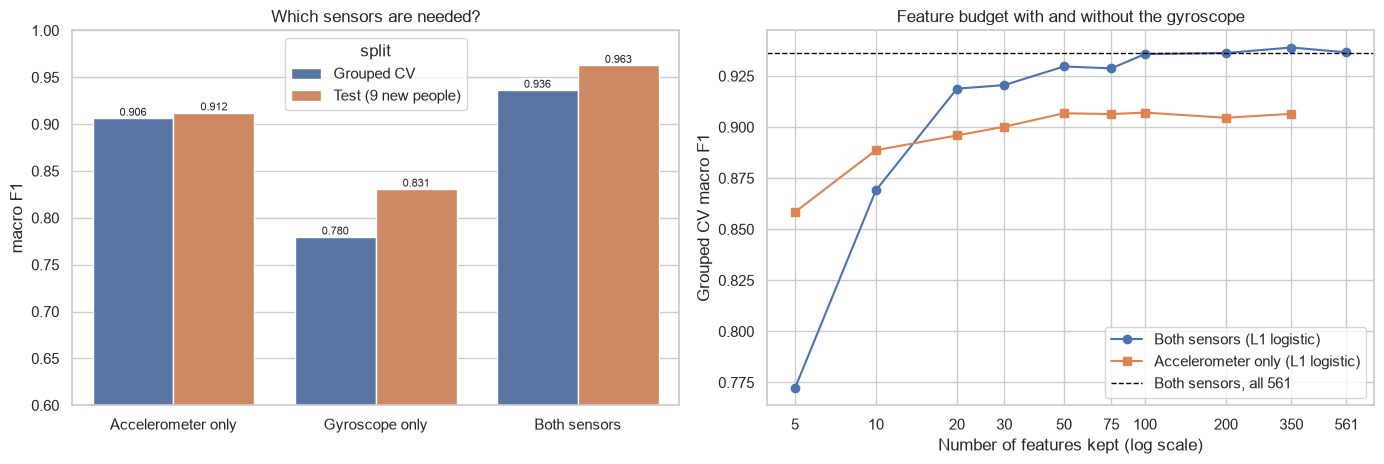

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

plot_df = sensor_table.reset_index(names="sensors").melt(
    id_vars="sensors", value_vars=["cv_f1_macro", "test_f1_macro"],
    var_name="split", value_name="macro F1")
plot_df["split"] = plot_df["split"].map(
    {"cv_f1_macro": "Grouped CV", "test_f1_macro": "Test (9 new people)"})
sns.barplot(data=plot_df, x="sensors", y="macro F1", hue="split",
            ax=axes[0])
axes[0].set_ylim(0.6, 1.0)
axes[0].set_xlabel("")
axes[0].set_title("Which sensors are needed?")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8)

all_part = curve[curve["method"] == best_method]
axes[1].plot(all_part["k"], all_part["cv_f1_macro"], "o-",
             label=f"Both sensors ({best_method})")
axes[1].plot(acc_curve["k"], acc_curve["cv_f1_macro"], "s-",
             label=f"Accelerometer only ({best_method})")
axes[1].axhline(full_cv_f1, color="black", linestyle="--", linewidth=1,
                label="Both sensors, all 561")
axes[1].set_xscale("log")
axes[1].set_xticks(K_VALUES)
axes[1].set_xticklabels(K_VALUES)
axes[1].set_xlabel("Number of features kept (log scale)")
axes[1].set_ylabel("Grouped CV macro F1")
axes[1].set_title("Feature budget with and without the gyroscope")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "B_sensor_comparison")
plt.show()

**Observations.**

* **The accelerometer carries most of the signal.** On its own it keeps CV macro F1 0.907 (test 0.912), compared with 0.936 (test 0.963) for both sensors. The gyroscope on its own is much weaker (CV 0.780, test 0.831). It cannot measure gravity, so it cannot tell how the phone is oriented, and that is what separates the three still postures.
* **The gyroscope still adds about 3 to 5 points.** Dropping it is a real trade-off, not a free saving.
* **Accelerometer only with feature selection.** With the L1 ranking applied to accelerometer features only, 30 features already reach CV macro F1 0.900, within 1 point of all 348 accelerometer features. The accelerometer curve is flat from about 20 features on, so after removing the gyroscope, extra features buy very little.
* The fold-to-fold spread is large (standard deviation about 0.04), so differences of 1 point between nearby k values are not meaningful.

## 6. PCA vs. feature selection

PCA compresses all 561 features into k new axes. It can keep a lot of
information in few dimensions, but each component mixes hundreds of
features, so the phone **still has to compute every feature** and the
result is hard to explain. Selected features are cheaper and readable.

,PCA components,L1 logistic features,difference (selection - PCA)
k,,,
5,0.7715,0.7722,0.0006
10,0.8207,0.8691,0.0484
20,0.8684,0.9188,0.0504
30,0.8744,0.9206,0.0462
50,0.8946,0.9297,0.0350
75,0.9022,0.9287,0.0265
100,0.9100,0.9358,0.0258
200,0.9243,0.9363,0.0120
350,0.9362,0.9390,0.0028


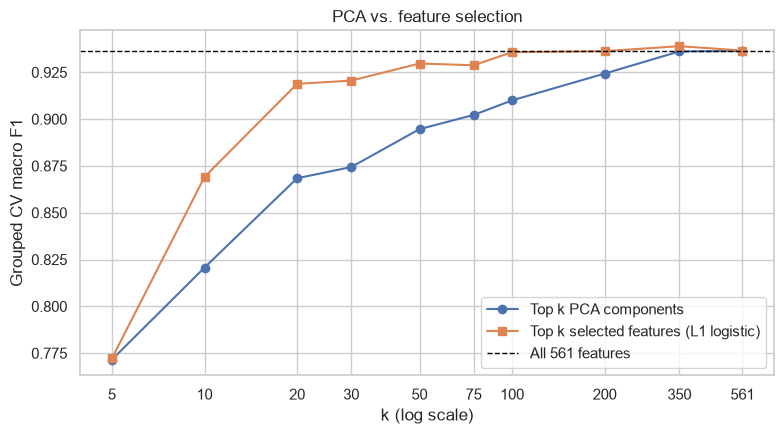

In [14]:
pca_part = curve[curve["method"] == "PCA"].set_index("k")
sel_part = curve[curve["method"] == best_method].set_index("k")
pca_vs_sel = pd.DataFrame({
    "PCA components": pca_part["cv_f1_macro"],
    f"{best_method} features": sel_part["cv_f1_macro"],
})
pca_vs_sel["difference (selection - PCA)"] = (
    pca_vs_sel.iloc[:, 1] - pca_vs_sel.iloc[:, 0])
save_results(pca_vs_sel, "B_pca_vs_selection")
display(pca_vs_sel)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pca_part.index, pca_part["cv_f1_macro"], "o-",
        label="Top k PCA components")
ax.plot(sel_part.index, sel_part["cv_f1_macro"], "s-",
        label=f"Top k selected features ({best_method})")
ax.axhline(full_cv_f1, color="black", linestyle="--", linewidth=1,
           label="All 561 features")
ax.set_xscale("log")
ax.set_xticks(K_VALUES)
ax.set_xticklabels(K_VALUES)
ax.set_xlabel("k (log scale)")
ax.set_ylabel("Grouped CV macro F1")
ax.set_title("PCA vs. feature selection")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "B_pca_vs_selection")
plt.show()

**Observations.** For every k from 10 to 200, **selected features beat the same number of PCA components**, by about 3.5 to 5 points of macro F1 at k = 10 to 50 (for example 0.919 vs. 0.868 at k = 20). PCA only catches up at about 350 components. PCA picks directions of highest *variance*, but in this dataset much of the variance is between people (how each person moves), not between activities. The L1 ranking looks at the labels directly. Selected features are also cheaper: PCA still needs all 561 features to be computed on the phone before it projects them.

## 7. Final comparison on the test set and recommendation

The candidate models below were all chosen from cross-validation. Each is
trained once on the full training set (rankings included) and scored once
on the 9 test people.

In [15]:
acc_order = rank_features(best_method, X_train[acc_cols], y_train)
candidates = {
    "Both sensors, all 561": X_train.columns,
    f"Both sensors, top {k_best}":
        X_train.columns[full_rankings[best_method][:k_best]],
    f"Accelerometer only, all {len(acc_cols)}": acc_cols,
    f"Accelerometer only, top {k_acc}": acc_cols[acc_order[:k_acc]],
    "Gyroscope only, all 213": X_train.columns[masks["gyroscope"]],
}
final_rows, final_preds = {}, {}
for name, cols in candidates.items():
    cv = cv_score(best_model(), X_train[cols], y_train, groups)
    test, pred = evaluate_on_test(best_model(), X_train[cols], y_train,
                                  X_test[cols], y_test)
    final_rows[name] = {"n_features": len(cols), "cv_f1_macro":
                        cv["cv_f1_macro"], **test}
    final_preds[name] = pred
final = pd.DataFrame(final_rows).T
final["f1_kept_vs_all"] = (final["test_f1_macro"]
                           / final.loc["Both sensors, all 561",
                                       "test_f1_macro"])
save_results(final, "B_final_comparison")
display(final)

,n_features,cv_f1_macro,test_accuracy,test_f1_macro,fit_time_s,predict_time_s,f1_kept_vs_all
"Both sensors, all 561",561.0,0.9364,0.9620,0.9629,3.1377,0.0073,1.0000
"Both sensors, top 50",50.0,0.9396,0.9423,0.9416,0.1140,0.0015,0.9779
"Accelerometer only, all 348",348.0,0.9065,0.9101,0.9122,2.0251,0.0060,0.9474
"Accelerometer only, top 30",30.0,0.9158,0.8897,0.8888,0.0756,0.0014,0.9231
"Gyroscope only, all 213",213.0,0.7797,0.8283,0.8308,2.6919,0.0035,0.8628


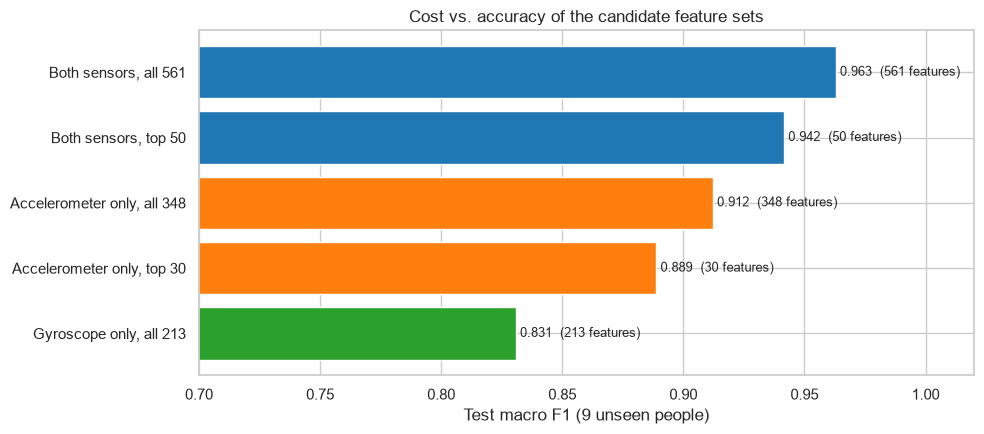

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = final.sort_values("test_f1_macro").index
bars = ax.barh(order, final.loc[order, "test_f1_macro"],
               color=["tab:orange" if "Accelerometer" in n else
                      "tab:green" if "Gyroscope" in n else "tab:blue"
                      for n in order])
ax.bar_label(bars, labels=[f"{final.loc[n, 'test_f1_macro']:.3f}  "
                           f"({final.loc[n, 'n_features']:.0f} features)"
                           for n in order], padding=3, fontsize=9)
ax.set_xlim(0.7, 1.02)
ax.set_xlabel("Test macro F1 (9 unseen people)")
ax.set_title("Cost vs. accuracy of the candidate feature sets")
fig.tight_layout()
save_figure(fig, "B_final_comparison")
plt.show()

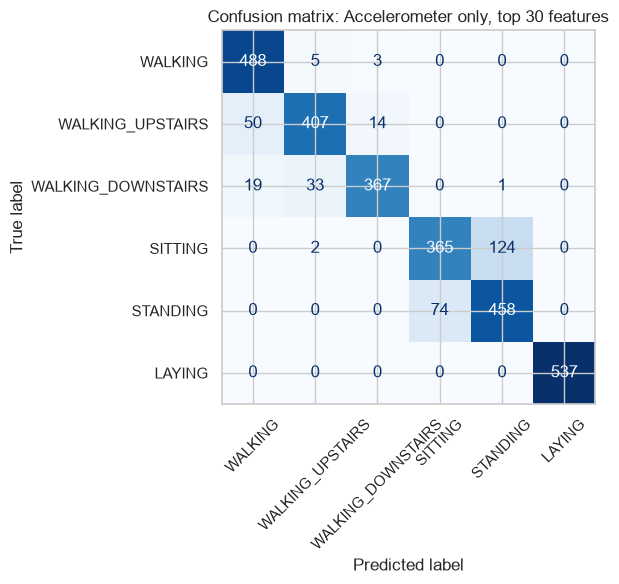

                    precision    recall  f1-score   support

           WALKING      0.876     0.984     0.927       496
  WALKING_UPSTAIRS      0.911     0.864     0.887       471
WALKING_DOWNSTAIRS      0.956     0.874     0.913       420
           SITTING      0.831     0.743     0.785       491
          STANDING      0.786     0.861     0.822       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.890      2947
         macro avg      0.893     0.888     0.889      2947
      weighted avg      0.892     0.890     0.889      2947



In [17]:
recommended = f"Accelerometer only, top {k_acc}"
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_preds[recommended], display_labels=labels,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix: {recommended} features")
fig.tight_layout()
save_figure(fig, "B_confusion_matrix")
plt.show()
print(classification_report(y_test, final_preds[recommended],
                            target_names=labels, digits=3))

### 7.1 What do the selected features mean?

Feature names in this dataset follow a pattern, for example
`tGravityAcc-min()-X`: `t` (time) or `f` (frequency, after an FFT), the
signal (body motion or gravity, accelerometer or gyroscope, optionally its
jerk or magnitude), the statistic, and the axis. The helper below turns a
name into plain English.

In [18]:
_STATS = {
    "mean": "average", "std": "standard deviation",
    "mad": "median absolute deviation", "max": "maximum", "min": "minimum",
    "sma": "signal magnitude area", "energy": "energy (sum of squares)",
    "iqr": "interquartile range", "entropy": "entropy",
    "arCoeff": "autoregression coefficient", "correlation":
    "correlation between axes", "maxInds": "frequency with the most energy",
    "meanFreq": "weighted mean frequency", "skewness": "skewness",
    "kurtosis": "kurtosis", "bandsEnergy": "energy in frequency band",
}
_BANDS_AXIS = {"": "X", "__1": "Y", "__2": "Z"}


def _signal_text(signal):
    """Describe a signal name such as 'tBodyAccJerkMag' in words."""
    domain = "frequency-domain" if signal.startswith("f") else "time-domain"
    signal = signal[1:].replace("BodyBody", "Body")
    parts = []
    parts.append("gravity" if signal.startswith("Gravity") else "body")
    parts.append("gyroscope" if "Gyro" in signal else "acceleration")
    if "Jerk" in signal:
        parts.append("jerk (rate of change)")
    if "Mag" in signal:
        parts.append("magnitude")
    return f"{domain} {' '.join(parts)}"


def describe_feature(name):
    """Return a plain-English description of a UCI HAR feature name."""
    base, _, dup = name.partition("__")
    dup = f"__{dup}" if dup else ""
    angle = re.match(r"angle\((\w+),\s*(\w+)\)", base)
    if angle:
        first = angle.group(1).replace("Mean", "").replace("Jerk", " jerk")
        first = (f"the phone's {first} axis" if len(first) == 1
                 else _signal_text(first))
        return f"angle between {first} and the average gravity direction"
    signal, stat, *rest = base.split("-")
    stat_key = stat.replace("()", "").split("(")[0]
    text = f"{_STATS.get(stat_key, stat_key)} of {_signal_text(signal)}"
    if stat_key == "bandsEnergy":
        text += f", bins {rest[0]}, {_BANDS_AXIS[dup]} axis"
    elif rest:
        text += f", {rest[0].replace(',', ' and ')} axis"
    return text


def sensor_of(name):
    """Return which phone sensor a feature comes from."""
    return "gyroscope" if "Gyro" in name else "accelerometer"


chosen = list(candidates[recommended])
chosen_table = pd.DataFrame({
    "feature": chosen,
    "meaning": [describe_feature(n) for n in chosen],
    "sensor": [sensor_of(n) for n in chosen],
}, index=pd.RangeIndex(1, len(chosen) + 1, name="rank"))
save_results(chosen_table, "B_top_features")
with pd.option_context("display.max_colwidth", 90):
    display(chosen_table)

,feature,meaning,sensor
rank,,,
1,tGravityAcc-min()-X,"minimum of time-domain gravity acceleration, X axis",accelerometer
2,tGravityAcc-max()-Y,"maximum of time-domain gravity acceleration, Y axis",accelerometer
3,fBodyAccMag-energy(),energy (sum of squares) of frequency-domain body acceleration magnitude,accelerometer
4,tGravityAcc-mean()-X,"average of time-domain gravity acceleration, X axis",accelerometer
5,tBodyAccJerk-entropy()-Z,"entropy of time-domain body acceleration jerk (rate of change), Z axis",accelerometer
6,"fBodyAcc-bandsEnergy()-1,8","energy in frequency band of frequency-domain body acceleration, bins 1,8, X axis",accelerometer
7,tGravityAcc-energy()-Y,"energy (sum of squares) of time-domain gravity acceleration, Y axis",accelerometer
8,"fBodyAcc-bandsEnergy()-1,8__1","energy in frequency band of frequency-domain body acceleration, bins 1,8, Y axis",accelerometer
9,fBodyAccJerk-max()-Y,"maximum of frequency-domain body acceleration jerk (rate of change), Y axis",accelerometer


In [19]:
consensus = rank_table.head(20).copy()
consensus.insert(0, "meaning", [describe_feature(n) for n in consensus.index])
save_results(consensus, "B_consensus_top20")
with pd.option_context("display.max_colwidth", 80):
    display(consensus)

,meaning,Random forest,Mutual information,L1 logistic,mean rank
tGravityAcc-max()-Y,"maximum of time-domain gravity acceleration, Y axis",7,4,8,6.3333
tGravityAcc-min()-Y,"minimum of time-domain gravity acceleration, Y axis",6,2,12,6.6667
tGravityAcc-mean()-Y,"average of time-domain gravity acceleration, Y axis",4,24,14,14.0000
tGravityAcc-min()-X,"minimum of time-domain gravity acceleration, X axis",2,45,1,16.0000
fBodyAccMag-energy(),energy (sum of squares) of frequency-domain body acceleration magnitude,26,41,2,23.0000
tBodyAccJerk-max()-X,"maximum of time-domain body acceleration jerk (rate of change), X axis",60,3,13,25.3333
"fBodyAcc-bandsEnergy()-1,8","energy in frequency band of frequency-domain body acceleration, bins 1,8, X ...",82,10,5,32.3333
fBodyAcc-mad()-X,"median absolute deviation of frequency-domain body acceleration, X axis",24,19,57,33.3333
tBodyAcc-max()-X,"maximum of time-domain body acceleration, X axis",36,1,84,40.3333
tGravityAcc-max()-X,"maximum of time-domain gravity acceleration, X axis",9,148,4,53.6667


**Observations and recommendation.**

| Feature set | Features | Test macro F1 | Share of full accuracy | Fit time |
|---|---|---|---|---|
| Both sensors, all | 561 | 0.963 | 100% | 3.1 s |
| Both sensors, top 50 (L1) | 50 | 0.942 | 97.8% | 0.11 s |
| Accelerometer only, all | 348 | 0.912 | 94.7% | 2.0 s |
| Accelerometer only, top 30 (L1) | 30 | 0.889 | 92.3% | 0.08 s |
| Gyroscope only, all | 213 | 0.831 | 86.3% | 2.7 s |

1. **Best accuracy for the cost: both sensors, top 50 L1 features.** This keeps 97.8% of the full model's macro F1 with 9% of the features, and trains about 28 times faster. It is the recommended configuration when the gyroscope is available.
2. **Cheapest configuration: accelerometer only, 30 features.** This drops the power-hungry gyroscope and 95% of the features, and still reaches 0.889 macro F1 (89.0% accuracy) on people the model never saw. In cross-validation it scored as well as all 348 accelerometer features (0.916 vs. 0.907), but on the test set it lost about 2 points against them. This gap is within the person-to-person spread we saw in cross-validation (standard deviation about 0.04). For a battery-limited app, all 348 accelerometer features (0.912) is a safe middle ground. Computing features costs much less than running the gyroscope.
3. **Where the cheap model fails.** The confusion matrix shows that lying is still perfect (F1 1.000) and walking stays high. Almost all the loss is **sitting vs. standing** (F1 0.785 and 0.822), the same pair Person A identified as the hardest. The rest is mixing among the three walking activities (upstairs and downstairs recall 0.86 to 0.87). Without the gyroscope, the model loses the rotation cues that help separate these.
4. **What the model looks at.** The most important features are **gravity-direction** features (average, min and max of `tGravityAcc` on X and Y, which describe phone orientation, that is, posture) and **low-frequency body-motion energy and jerk** (how intensely the person moves). In plain terms: *"Which way is the phone pointing, and how much is it shaking?"* answers most of the question.

**Takeaway for the report:** *Accelerometer only with 30 features keeps about 92% of the full model's macro F1 (0.889 vs. 0.963). Adding the gyroscope and using 50 selected features keeps about 98% (0.942). In both cases the remaining errors are mostly sitting vs. standing.*